# From genes to prognosis: predicting breast-cancer mortality from clinical and genomic data (METABRIC)

**Machine Learning 1 capstone, Tek-Up, ING-4 SDIA, 2026–2027**
**Team:** Oumaima Hafiane, Imen Hichri

# 1. Problem Statement

## Problem description
Breast cancer is the most commonly diagnosed cancer in women worldwide. After diagnosis, oncologists estimate each patient's prognosis to decide how aggressive the treatment should be. A standard tool is the Nottingham Prognostic Index (NPI), a simple formula based on three clinical measurements: tumor size, number of positive lymph nodes and tumor grade. The METABRIC study adds molecular data for 1,904 patients: the expression of 489 genes and the mutation status of 173 genes. Our question is: **do gene expression and mutations predict death from breast cancer better than clinical data alone, and better than the NPI that oncologists already use?**

## Task type
Supervised **binary classification**.

- **Target:** `y = 1` if `death_from_cancer == "Died of Disease"` (622 patients, 33%), `y = 0` otherwise ("Living" or "Died of Other Causes").
- **Features:** 27 clinical variables (age, tumor size, grade, receptor status, treatments, ...), 489 gene-expression z-scores and 173 gene-mutation indicators.
- **Excluded to avoid leakage:** `overall_survival`, `overall_survival_months`, `death_from_cancer`, `patient_id`.

## Primary metric: ROC-AUC
- **Accuracy is misleading here:** a model that predicts "no death" for everyone already reaches 67% accuracy while detecting no patient at risk.
- **ROC-AUC measures ranking quality:** it is the probability that a patient who died of the disease receives a higher risk score than a patient who did not. It does not depend on a decision threshold.
- **It allows a fair comparison with the NPI:** the NPI is a score, not a yes/no prediction, so it can be evaluated with ROC-AUC exactly like our models.

**Secondary metrics:** recall, precision and F1 for the positive class, and the precision–recall curve (PR-AUC). Recall matters most among them, because missing a high-risk patient (false negative) is more costly than a false alarm.

## Why it matters and who would use it
A better prognosis estimate helps avoid under-treating high-risk patients and over-treating low-risk ones. The end users would be oncologists and cancer researchers. Measuring gene expression is expensive, so it is also useful to know whether it adds predictive value beyond cheap clinical measurements. This project is an academic study, not a clinical tool.

## Known limitation
Patients were followed for different lengths of time, so some "Living" patients may have died of the disease after the study ended. The proper tool for this is survival analysis, which is outside the scope of this course. We treat the problem as binary classification and discuss this limitation in the conclusion.

# 2. Data Loading & Dictionary

**What the next cell does:** imports the libraries used in sections 2 and 3 and sets the global configuration.
- `SEED = 42` fixes the random seed so results are reproducible.
- The `plt` and `sns` lines set a default size and style for all plots.
- `C0` (blue) and `C1` (orange) are the two colours used in every plot: blue for patients who did not die of the disease, orange for those who did.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')
pd.set_option('display.max_colwidth', None)

C0, C1 = '#2a78d6', '#eb6834'          # class 0 (blue), class 1 (orange)
CMAP_DIV = LinearSegmentedColormap.from_list('blue_orange', [C0, '#f0efec', C1])

**What the next cell does:** reads the CSV into the DataFrame `df`, then prints its shape and checks for duplicated rows and duplicated patient IDs.
- The path starts with `../` because the notebook is in `notebooks/` and the data is in `data/raw/`.
- `low_memory=False` makes pandas read each column in one pass, so the mutation columns (which mix `"0"` and text codes) get one consistent type.

In [22]:
DATA_PATH = '../data/raw/METABRIC_RNA_Mutation.csv'
df = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Shape: {df.shape}")
print(f"Duplicated rows: {df.duplicated().sum()}")
print(f"Duplicated patient IDs: {df['patient_id'].duplicated().sum()}")
df.head()

Shape: (1904, 693)
Duplicated rows: 0
Duplicated patient IDs: 0


,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_+_claudin-low_subtype,cohort,er_status_measured_by_ihc,...,mtap_mut,ppp2cb_mut,smarcd1_mut,nras_mut,ndfip1_mut,hras_mut,prps2_mut,smarcb1_mut,stmn2_mut,siah1_mut
0,0,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,0,claudin-low,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
1,2,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,0,LumA,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
2,5,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
3,6,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
4,8,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0


**What the next cell does:** splits the 693 column names into three lists that are reused in the whole project.
- `clinical_cols`: the first 31 columns.
- `mut_cols`: the columns whose name ends with `_mut`.
- `expr_cols`: everything else, which is the gene-expression columns.

The `assert` stops the notebook if the counts are not 31 / 489 / 173, so a wrong file is detected immediately.

In [23]:
clinical_cols = df.columns[:31].tolist()
mut_cols = [c for c in df.columns if c.endswith('_mut')]
expr_cols = [c for c in df.columns if c not in clinical_cols and c not in mut_cols]

print(f"Clinical: {len(clinical_cols)} | Gene expression: {len(expr_cols)} | Mutations: {len(mut_cols)}")
assert (len(clinical_cols), len(expr_cols), len(mut_cols)) == (31, 489, 173)

Clinical: 31 | Gene expression: 489 | Mutations: 173


**What the next cell does:** shows the structure of the data with `info()`: the type of each column and how many values are not missing.
- On the full table pandas only prints a summary, because there are 693 columns.
- On the clinical columns it prints one line per column.

In [24]:
df.info()
df[clinical_cols].info()

<class 'pandas.DataFrame'>
RangeIndex: 1904 entries, 0 to 1903
Columns: 693 entries, patient_id to siah1_mut
dtypes: float64(498), int64(5), str(190)
memory usage: 10.1 MB
<class 'pandas.DataFrame'>
RangeIndex: 1904 entries, 0 to 1903
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   patient_id                      1904 non-null   int64  
 1   age_at_diagnosis                1904 non-null   float64
 2   type_of_breast_surgery          1882 non-null   str    
 3   cancer_type                     1904 non-null   str    
 4   cancer_type_detailed            1889 non-null   str    
 5   cellularity                     1850 non-null   str    
 6   chemotherapy                    1904 non-null   int64  
 7   pam50_+_claudin-low_subtype     1904 non-null   str    
 8   cohort                          1904 non-null   float64
 9   er_status_measured_by_ihc       1874 non-null   str    


**What the next cell does:** computes descriptive statistics with `describe()`.
1. Numerical clinical columns: count, mean, standard deviation, min, quartiles, max.
2. Categorical clinical columns: number of categories and the most frequent one.
3. Gene expression: mean, std, min and max of each gene, then a summary of these four numbers across the 489 genes (to check they are z-scores: mean near 0, std near 1).
4. Mutations: the share of cells that are not `"0"`, and a check that there are no missing values outside the clinical columns.

In [25]:
display(df[clinical_cols].describe().T.round(2))
display(df[clinical_cols].describe(exclude='number').T)

expr_stats = df[expr_cols].agg(['mean', 'std', 'min', 'max']).T
display(expr_stats.describe().round(2))

mutated = df[mut_cols].astype(str) != '0'
print(f"Mutated cells: {mutated.mean().mean():.1%}")
print(f"Missing values outside clinical columns: {df[expr_cols + mut_cols].isna().sum().sum()}")

,count,mean,std,min,25%,50%,75%,max
patient_id,1904.0,3921.98,2358.48,0.00,896.50,4730.50,5536.25,7299.00
age_at_diagnosis,1904.0,61.09,12.98,21.93,51.38,61.77,70.59,96.29
chemotherapy,1904.0,0.21,0.41,0.00,0.00,0.00,0.00,1.00
cohort,1904.0,2.64,1.23,1.00,1.00,3.00,3.00,5.00
neoplasm_histologic_grade,1832.0,2.42,0.65,1.00,2.00,3.00,3.00,3.00
hormone_therapy,1904.0,0.62,0.49,0.00,0.00,1.00,1.00,1.00
lymph_nodes_examined_positive,1904.0,2.00,4.08,0.00,0.00,0.00,2.00,45.00
mutation_count,1859.0,5.70,4.06,1.00,3.00,5.00,7.00,80.00
nottingham_prognostic_index,1904.0,4.03,1.14,1.00,3.05,4.04,5.04,6.36
overall_survival_months,1904.0,125.12,76.33,0.00,60.83,115.62,184.72,355.20


,count,unique,top,freq
type_of_breast_surgery,1882,2,MASTECTOMY,1127
cancer_type,1904,2,Breast Cancer,1903
cancer_type_detailed,1889,6,Breast Invasive Ductal Carcinoma,1500
cellularity,1850,3,High,939
pam50_+_claudin-low_subtype,1904,7,LumA,679
er_status_measured_by_ihc,1874,2,Positve,1445
er_status,1904,2,Positive,1459
her2_status_measured_by_snp6,1904,4,NEUTRAL,1383
her2_status,1904,2,Negative,1668
tumor_other_histologic_subtype,1889,8,Ductal/NST,1454


,mean,std,min,max
count,489.0,489.0,489.00,489.00
mean,-0.0,1.0,-3.05,5.80
std,0.0,0.0,1.04,2.75
min,-0.0,1.0,-7.24,2.00
25%,-0.0,1.0,-3.62,4.15
50%,-0.0,1.0,-2.96,5.13
75%,0.0,1.0,-2.31,6.50
max,0.0,1.0,-0.92,20.40


Mutated cells: 3.0%
Missing values outside clinical columns: 0


**What the next cell does:** builds the data dictionary.
- `clinical_dict` is written by hand: one line per clinical column with its type, meaning and unit.
- The columns `Dtype`, `Unique values` and `Missing %` are computed from `df`, so they always match the real data.
- Two extra rows describe the 489 gene-expression columns and the 173 mutation columns as groups.

In [26]:
clinical_dict = [
    # (feature, type, description, unit)
    ('patient_id', 'Identifier', 'Patient identifier (not a feature)', '-'),
    ('age_at_diagnosis', 'Numerical, continuous', 'Age of the patient at diagnosis', 'years'),
    ('type_of_breast_surgery', 'Categorical, binary', 'Mastectomy or breast-conserving surgery', '-'),
    ('cancer_type', 'Categorical, nominal', 'Breast cancer or breast sarcoma', '-'),
    ('cancer_type_detailed', 'Categorical, nominal', 'Detailed histological type (ductal, lobular, mixed, ...)', '-'),
    ('cellularity', 'Categorical, ordinal', 'Proportion of tumor cells in the sample: Low < Moderate < High', '-'),
    ('chemotherapy', 'Categorical, binary', 'Patient received chemotherapy (1) or not (0)', '-'),
    ('pam50_+_claudin-low_subtype', 'Categorical, nominal', 'Molecular subtype from the PAM50 gene signature (LumA, LumB, Her2, Basal, ...)', '-'),
    ('cohort', 'Categorical, nominal', 'Group of patients the sample belongs to in the study (1 to 5)', '-'),
    ('er_status_measured_by_ihc', 'Categorical, binary', 'Estrogen-receptor status measured by immunohistochemistry', '-'),
    ('er_status', 'Categorical, binary', 'Estrogen-receptor status (Positive / Negative)', '-'),
    ('neoplasm_histologic_grade', 'Categorical, ordinal', 'How abnormal the tumor cells look: 1 (low) to 3 (high)', '-'),
    ('her2_status_measured_by_snp6', 'Categorical, nominal', 'HER2 gene copy number measured by SNP6 array (neutral, gain, loss)', '-'),
    ('her2_status', 'Categorical, binary', 'HER2 receptor status (Positive / Negative)', '-'),
    ('tumor_other_histologic_subtype', 'Categorical, nominal', 'Histological subtype (Ductal/NST, Lobular, Mixed, ...)', '-'),
    ('hormone_therapy', 'Categorical, binary', 'Patient received hormone therapy (1) or not (0)', '-'),
    ('inferred_menopausal_state', 'Categorical, binary', 'Pre- or post-menopausal, inferred from age', '-'),
    ('integrative_cluster', 'Categorical, nominal', 'Molecular subgroup (IntClust) defined by Curtis et al. 2012', '-'),
    ('primary_tumor_laterality', 'Categorical, binary', 'Breast affected: Left or Right', '-'),
    ('lymph_nodes_examined_positive', 'Numerical, discrete', 'Number of lymph nodes containing cancer cells', 'count'),
    ('mutation_count', 'Numerical, discrete', 'Number of mutated genes found in the tumor', 'count'),
    ('nottingham_prognostic_index', 'Numerical, continuous', 'NPI = 0.2 x size (cm) + lymph-node stage + grade; higher = worse prognosis', 'score'),
    ('oncotree_code', 'Categorical, nominal', 'OncoTree code of the cancer type (IDC, ILC, MDLC, ...)', '-'),
    ('overall_survival_months', 'Numerical, continuous', 'Time from diagnosis to death or last follow-up (LEAKAGE, removed)', 'months'),
    ('overall_survival', 'Categorical, binary', 'Alive (1) or dead (0) at last follow-up (LEAKAGE, removed)', '-'),
    ('pr_status', 'Categorical, binary', 'Progesterone-receptor status (Positive / Negative)', '-'),
    ('radio_therapy', 'Categorical, binary', 'Patient received radiotherapy (1) or not (0)', '-'),
    ('3-gene_classifier_subtype', 'Categorical, nominal', 'Subtype from a 3-gene classifier (ER, HER2, proliferation)', '-'),
    ('tumor_size', 'Numerical, continuous', 'Diameter of the tumor', 'mm'),
    ('tumor_stage', 'Categorical, ordinal', 'Stage of the cancer: 0 (early) to 4 (advanced)', '-'),
    ('death_from_cancer', 'Categorical, nominal', 'Living / Died of Disease / Died of Other Causes (source of the TARGET)', '-'),
]

data_dict = pd.DataFrame(clinical_dict, columns=['Feature', 'Type', 'Description', 'Unit'])
assert set(data_dict['Feature']) == set(clinical_cols)   # every clinical column is documented

data_dict['Dtype'] = data_dict['Feature'].map(df.dtypes.astype(str))
data_dict['Unique values'] = data_dict['Feature'].map(df[clinical_cols].nunique())
data_dict['Missing %'] = data_dict['Feature'].map((df[clinical_cols].isna().mean() * 100).round(1))

genomic_rows = pd.DataFrame([
    {'Feature': f'{len(expr_cols)} gene-expression columns (brca1, ...)', 'Type': 'Numerical, continuous',
     'Description': 'mRNA expression level of one gene, standardised across patients', 'Unit': 'z-score',
     'Dtype': 'float64', 'Unique values': '-', 'Missing %': 0.0},
    {'Feature': f'{len(mut_cols)} mutation columns (*_mut)', 'Type': 'Text, binarised later',
     'Description': '"0" = gene not mutated; otherwise the mutation code (e.g. H1047R)', 'Unit': '-',
     'Dtype': 'text', 'Unique values': '-', 'Missing %': 0.0},
])

data_dict = pd.concat([data_dict, genomic_rows], ignore_index=True)
data_dict

,Feature,Type,Description,Unit,Dtype,Unique values,Missing %
0,patient_id,Identifier,Patient identifier (not a feature),-,int64,1904,0.0
1,age_at_diagnosis,"Numerical, continuous",Age of the patient at diagnosis,years,float64,1572,0.0
2,type_of_breast_surgery,"Categorical, binary",Mastectomy or breast-conserving surgery,-,str,2,1.2
3,cancer_type,"Categorical, nominal",Breast cancer or breast sarcoma,-,str,2,0.0
4,cancer_type_detailed,"Categorical, nominal","Detailed histological type (ductal, lobular, mixed, ...)",-,str,6,0.8
5,cellularity,"Categorical, ordinal",Proportion of tumor cells in the sample: Low < Moderate < High,-,str,3,2.8
6,chemotherapy,"Categorical, binary",Patient received chemotherapy (1) or not (0),-,int64,2,0.0
7,pam50_+_claudin-low_subtype,"Categorical, nominal","Molecular subtype from the PAM50 gene signature (LumA, LumB, Her2, Basal, ...)",-,str,7,0.0
8,cohort,"Categorical, nominal",Group of patients the sample belongs to in the study (1 to 5),-,float64,5,0.0
9,er_status_measured_by_ihc,"Categorical, binary",Estrogen-receptor status measured by immunohistochemistry,-,str,2,1.6


**Summary.** The dataset has 1,904 patients and 693 columns, with no duplicated rows or patients. The columns form three groups: 31 clinical columns (numerical and categorical), 489 gene-expression z-scores and 173 mutation columns stored as text. Missing values appear only in the clinical columns. Four clinical columns will not be used as features: `patient_id` (identifier), and `overall_survival`, `overall_survival_months` and `death_from_cancer`, which are known only after the outcome.

# 3. Exploratory Data Analysis

**What the next cell does:** prepares a working copy for the EDA, so that `df` stays untouched.
- `eda` is a copy of `df` without the row whose `death_from_cancer` is missing (we cannot know its class).
- `eda['target']` is the binary target: 1 if the patient died of the disease, 0 otherwise.
- `num_feats` lists the five numerical clinical features studied below.
- `flag()` is a small helper used later: it writes numbers such as `2.0` as `2` and missing values as `Missing` in plot labels.

In [27]:
eda = df.dropna(subset=['death_from_cancer']).copy()
eda['target'] = (eda['death_from_cancer'] == 'Died of Disease').astype(int)
TARGET_LABELS = {0: 'Did not die of disease (0)', 1: 'Died of disease (1)'}

num_feats = ['age_at_diagnosis', 'tumor_size', 'lymph_nodes_examined_positive',
             'mutation_count', 'nottingham_prognostic_index']

def flag(v):
    """Readable label for a category value."""
    if pd.isna(v):
        return 'Missing'
    if isinstance(v, (int, float, np.integer, np.floating)):
        return str(int(v))
    return str(v)

print(f"Rows used in the EDA: {len(eda)} (1 row without target removed)")
print(f"Overall death-from-disease rate: {eda['target'].mean():.1%}")

Rows used in the EDA: 1903 (1 row without target removed)
Overall death-from-disease rate: 32.7%


## 3.1 Missing values

**What the next cell does:** computes the percentage of missing values in each clinical column and draws a horizontal bar chart of the columns that have at least one gap. It also counts how many rows have at least one missing value, which tells us whether dropping incomplete rows is an option.

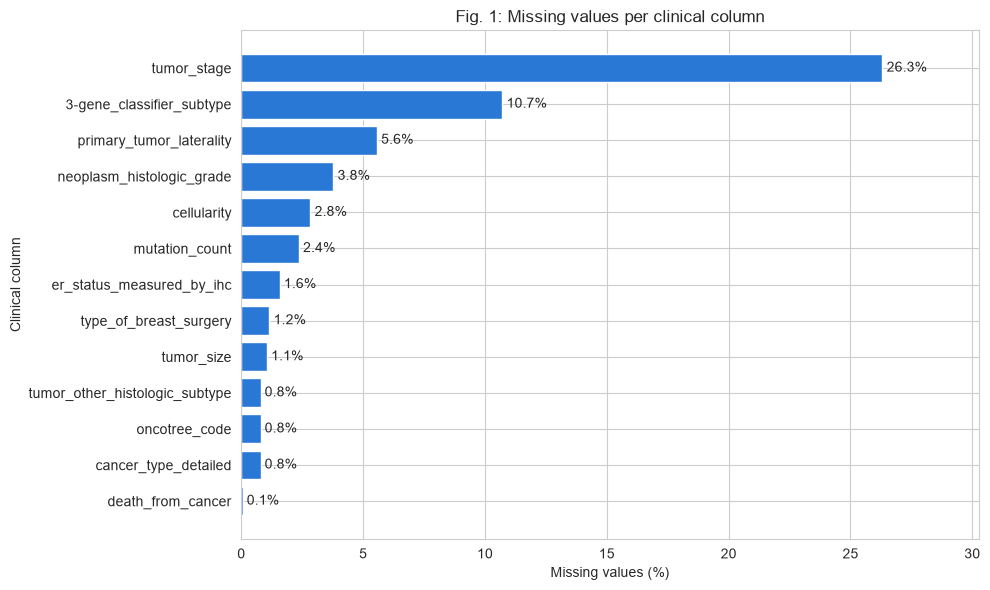

Columns with missing values: 13 of 31 clinical columns
Rows with at least one missing value: 812 (42.6%)
Missing values in gene-expression and mutation columns: 0


In [28]:
missing_pct = df[clinical_cols].isna().mean() * 100
missing_pct = missing_pct[missing_pct > 0].sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(missing_pct.index, missing_pct.values, color=C0)
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_title('Fig. 1: Missing values per clinical column')
ax.set_xlabel('Missing values (%)')
ax.set_ylabel('Clinical column')
ax.set_xlim(0, missing_pct.max() * 1.15)
plt.tight_layout()
plt.show()

rows_with_gap = df[clinical_cols].isna().any(axis=1).sum()
print(f"Columns with missing values: {len(missing_pct)} of {len(clinical_cols)} clinical columns")
print(f"Rows with at least one missing value: {rows_with_gap} ({rows_with_gap / len(df):.1%})")
print(f"Missing values in gene-expression and mutation columns: {df[expr_cols + mut_cols].isna().sum().sum()}")

**Interpretation.** Thirteen of the 31 clinical columns have missing values, led by `tumor_stage` (26.3%) and `3-gene_classifier_subtype` (10.7%), while every other column is at 5.6% or below. Because 812 rows (42.6%) have at least one gap, dropping incomplete rows would lose almost half of the patients, so missing values will be imputed inside the pipeline. The gene-expression and mutation columns are complete.

## 3.2 Target distribution

**What the next cell does:** draws two bar charts side by side.
- Left: the three original values of `death_from_cancer`.
- Right: the binary target we built from them.

It prints the counts and the imbalance ratio (number of class 0 patients for one class 1 patient), which is the value we will later use for class weights.

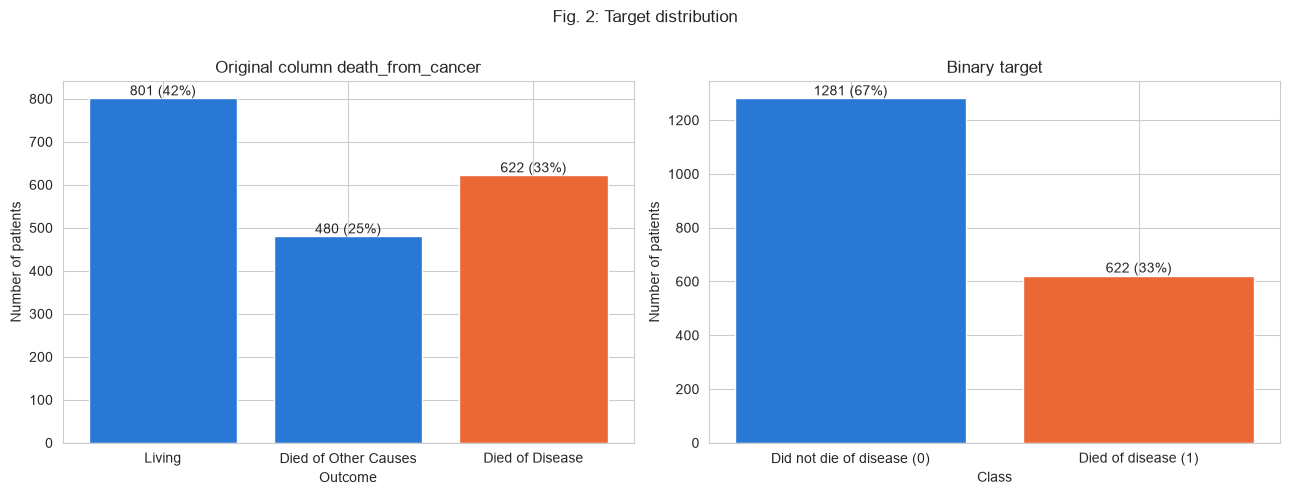

death_from_cancer
Living                  801
Died of Other Causes    480
Died of Disease         622

Class 0: 1281 | Class 1: 622 | ratio class 0 / class 1 = 2.06


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order3 = ['Living', 'Died of Other Causes', 'Died of Disease']
counts3 = eda['death_from_cancer'].value_counts().reindex(order3)
bars = axes[0].bar(counts3.index, counts3.values, color=[C0, C0, C1])
axes[0].bar_label(bars, labels=[f"{v} ({v / len(eda):.0%})" for v in counts3.values])
axes[0].set_title('Original column death_from_cancer')
axes[0].set_xlabel('Outcome')
axes[0].set_ylabel('Number of patients')

counts2 = eda['target'].value_counts().sort_index()
bars = axes[1].bar([TARGET_LABELS[i] for i in counts2.index], counts2.values, color=[C0, C1])
axes[1].bar_label(bars, labels=[f"{v} ({v / len(eda):.0%})" for v in counts2.values])
axes[1].set_title('Binary target')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Number of patients')

fig.suptitle('Fig. 2: Target distribution')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

print(counts3.to_string())
print(f"\nClass 0: {counts2[0]} | Class 1: {counts2[1]} | ratio class 0 / class 1 = {counts2[0] / counts2[1]:.2f}")

**Interpretation.** 622 patients (33%) died of the disease and 1,281 (67%) did not, which is a moderate imbalance with a ratio of 2.06 to 1. This confirms that accuracy is not a suitable metric, that the train/test split must be stratified, and that class weights of about 2 are appropriate for the positive class.

## 3.3 Leakage check

**What the next cell does:** checks the columns that are only known after the outcome.
- The first table crosses `overall_survival` with `death_from_cancer`: if one value of `overall_survival` matches one outcome exactly, the column gives the answer away.
- The second table shows the follow-up time (`overall_survival_months`) for each outcome.

No plot here: this cell justifies why these columns are removed from the features in Phase 4.

In [30]:
display(pd.crosstab(eda['overall_survival'], eda['death_from_cancer']))
display(eda.groupby('death_from_cancer')['overall_survival_months'].describe().round(1))

death_from_cancer,Died of Disease,Died of Other Causes,Living
overall_survival,,,
0,622,480,0
1,0,0,801


,count,mean,std,min,25%,50%,75%,max
death_from_cancer,,,,,,,,
Died of Disease,622.0,77.2,59.6,0.1,33.9,56.7,106.3,335.7
Died of Other Causes,480.0,129.5,70.3,2.3,76.2,122.4,179.5,355.2
Living,801.0,159.6,71.7,0.0,108.1,158.0,216.7,337.0


**Interpretation.** `overall_survival` equals 1 for all 801 living patients and 0 for all 1,102 patients who died, so it reveals the outcome. `overall_survival_months` is also known only after the outcome and differs strongly between groups (median 56.7 months for patients who died of the disease against 158.0 for living patients). Both columns are removed from the features, together with `death_from_cancer` and `patient_id`.

## 3.4 Univariate analysis: numerical features

**What the next cell does:** draws one histogram for each of the five numerical clinical features, with a dashed line at the median. Below the plot it prints the skewness of each feature: 0 means symmetric, and a large positive value means a long tail of high values.

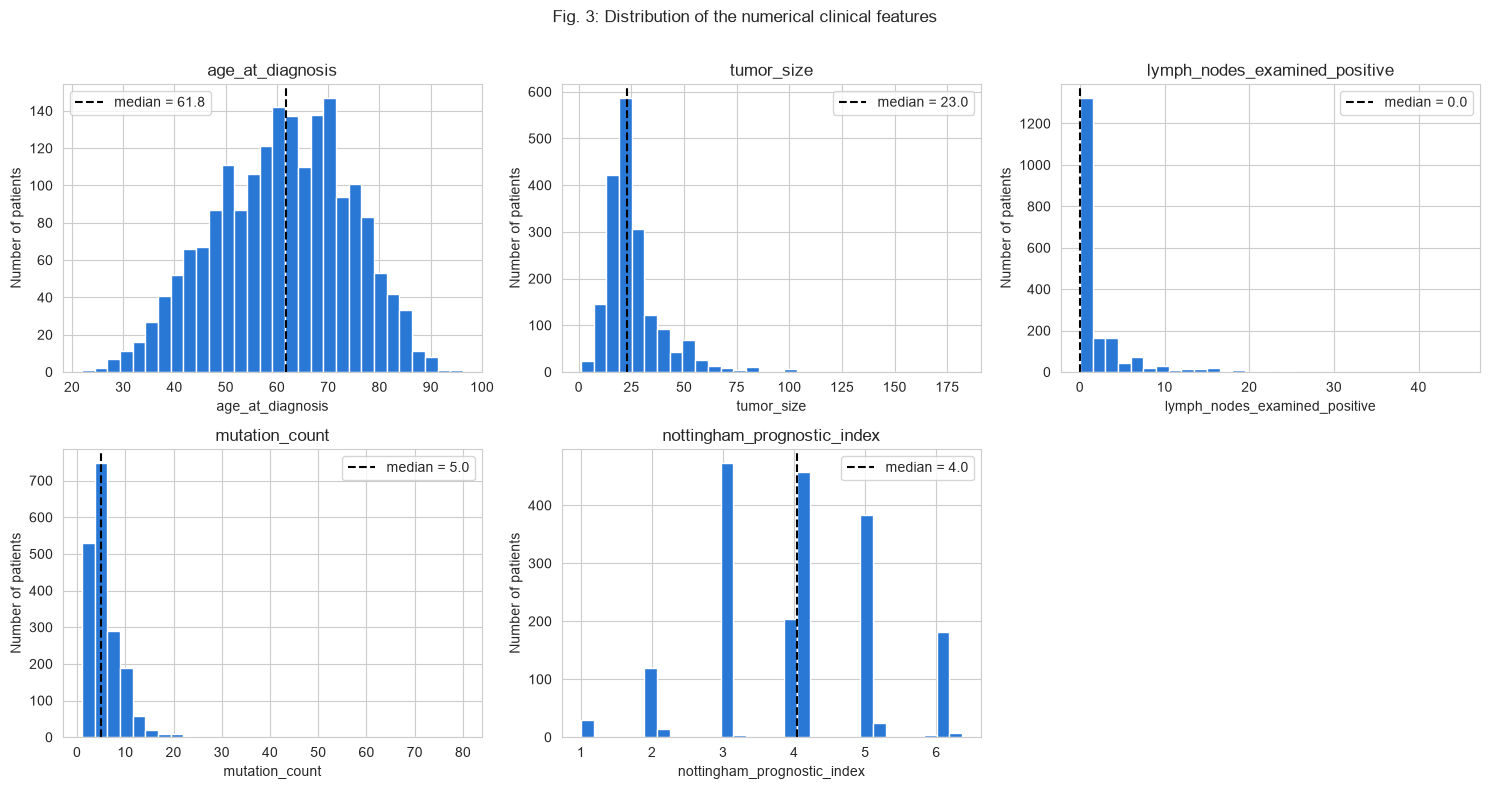

Skewness:
age_at_diagnosis                -0.19
tumor_size                       3.27
lymph_nodes_examined_positive    3.84
mutation_count                   5.20
nottingham_prognostic_index     -0.07


In [31]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, col in zip(axes, num_feats):
    values = eda[col].dropna()
    ax.hist(values, bins=30, color=C0, edgecolor='white')
    ax.axvline(values.median(), color='black', linestyle='--', label=f"median = {values.median():.1f}")
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Number of patients')
    ax.legend()
axes[-1].axis('off')
fig.suptitle('Fig. 3: Distribution of the numerical clinical features')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

print("Skewness:")
print(eda[num_feats].skew().round(2).to_string())

**Interpretation.** Age is roughly symmetric (median 61.8 years, skewness −0.19), whereas `tumor_size` (skewness 3.27), `lymph_nodes_examined_positive` (3.84, median 0) and `mutation_count` (5.20) are strongly right-skewed with a long tail of high values. The NPI is concentrated in bands close to whole numbers, because it adds two integer scores (grade and lymph-node stage) to a small term for tumor size.

## 3.5 Outlier detection

**What the next cell does:** looks for extreme values with two rules.
- **IQR rule:** a value is an outlier if it is below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR, where IQR = Q3 − Q1 is the range of the middle 50% of patients. This is the rule a box plot uses to draw its points.
- **Z-score rule:** a value is an outlier if it is more than 3 standard deviations from the mean.

The cell draws one box plot per feature and builds a table with the number of outliers found by each rule.

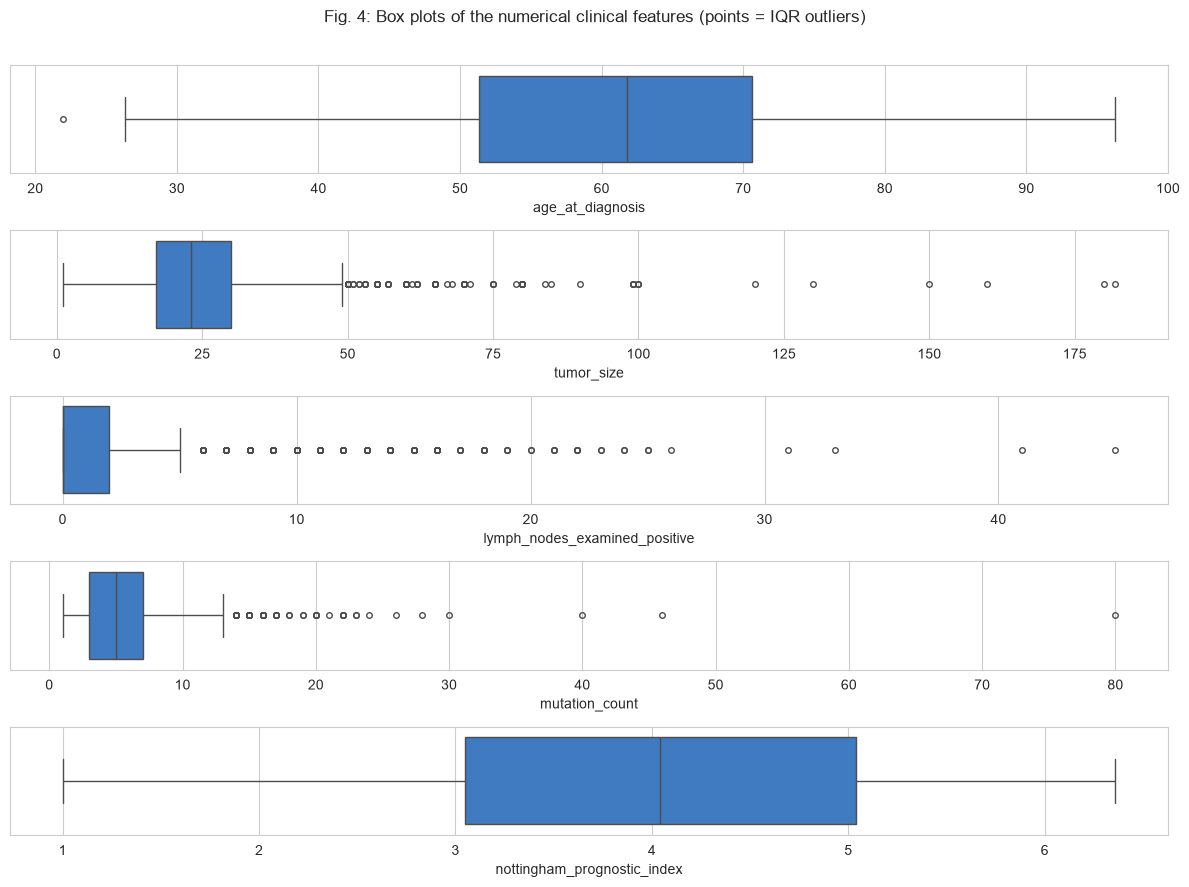

,Median,Max,IQR lower bound,IQR upper bound,Outliers (IQR),Outliers (|z| > 3)
Feature,,,,,,
age_at_diagnosis,61.78,96.29,22.53,99.43,1,1
tumor_size,23.00,182.00,-2.50,49.50,142,28
lymph_nodes_examined_positive,0.00,45.00,-3.00,5.00,210,50
mutation_count,5.00,80.00,-3.00,13.00,62,22
nottingham_prognostic_index,4.04,6.36,0.05,8.03,0,0


In [32]:
fig, axes = plt.subplots(len(num_feats), 1, figsize=(12, 9))
for ax, col in zip(axes, num_feats):
    sns.boxplot(x=eda[col], ax=ax, color=C0, flierprops={'marker': 'o', 'markersize': 4})
    ax.set_xlabel(col)
    ax.set_ylabel('')
fig.suptitle('Fig. 4: Box plots of the numerical clinical features (points = IQR outliers)')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

rows = []
for col in num_feats:
    s = eda[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    rows.append({'Feature': col, 'Median': s.median(), 'Max': s.max(),
                 'IQR lower bound': low, 'IQR upper bound': high,
                 'Outliers (IQR)': int(((s < low) | (s > high)).sum()),
                 'Outliers (|z| > 3)': int((z.abs() > 3).sum())})
outlier_table = pd.DataFrame(rows).set_index('Feature').round(2)
outlier_table

**Interpretation.** The IQR rule flags 142 values of `tumor_size` (above 49.5 mm), 210 of `lymph_nodes_examined_positive` (above 5) and 62 of `mutation_count` (above 13), while the stricter z-score rule flags 28, 50 and 22. These values are medically plausible (large tumors, many invaded lymph nodes) and describe exactly the high-risk patients we want to detect, so they are kept. Median imputation is used because the median is not affected by these extremes.

## 3.6 Univariate analysis: categorical features

**What the next cell does:** draws the value counts of twelve clinical categorical features as horizontal bars. Missing values are shown as their own bar called `Missing`. Features with a natural order (grade, stage, treatments coded 0/1) are sorted by value; the others are sorted by frequency.

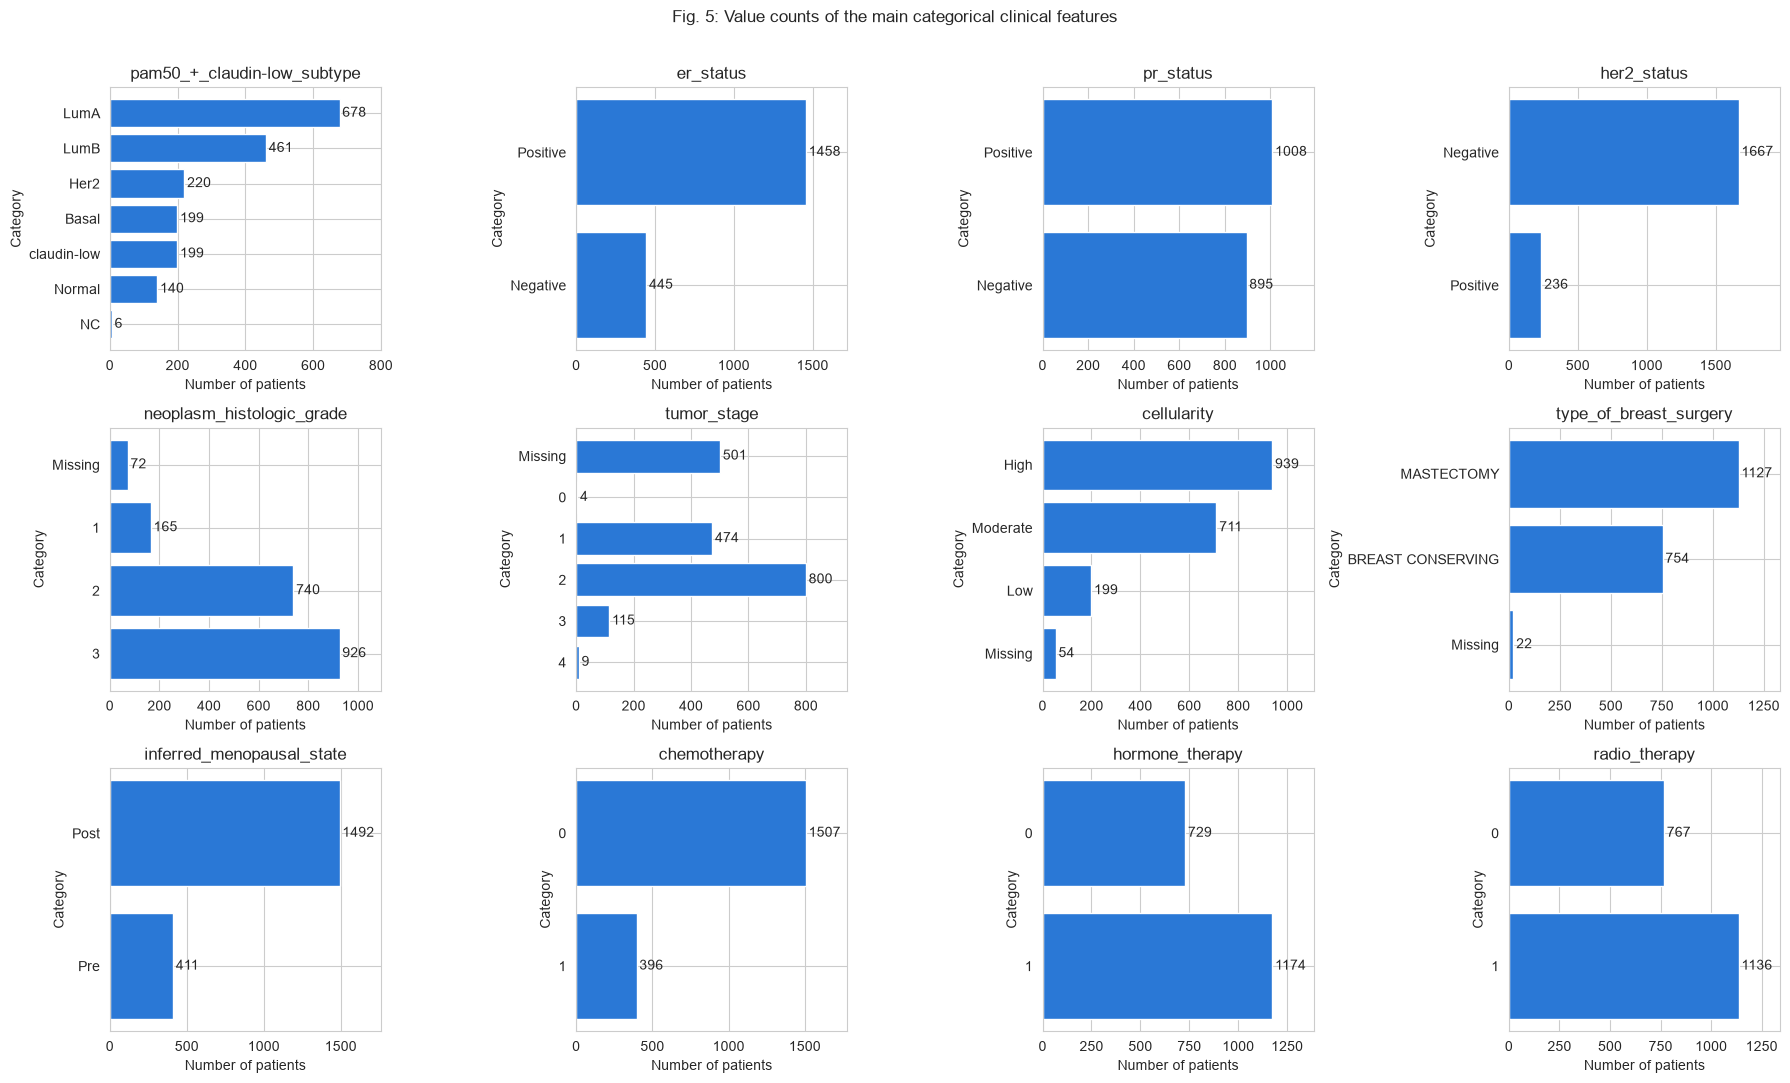

In [33]:
cat_feats = ['pam50_+_claudin-low_subtype', 'er_status', 'pr_status', 'her2_status',
             'neoplasm_histologic_grade', 'tumor_stage', 'cellularity', 'type_of_breast_surgery',
             'inferred_menopausal_state', 'chemotherapy', 'hormone_therapy', 'radio_therapy']

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), cat_feats):
    counts = eda[col].value_counts(dropna=False)
    if pd.api.types.is_numeric_dtype(eda[col]):
        counts = counts.sort_index(ascending=False)
    else:
        counts = counts.sort_values()
    bars = ax.barh([flag(v) for v in counts.index], counts.values, color=C0)
    ax.bar_label(bars, padding=2)
    ax.set_title(col)
    ax.set_xlabel('Number of patients')
    ax.set_ylabel('Category')
    ax.set_xlim(0, counts.max() * 1.18)
fig.suptitle('Fig. 5: Value counts of the main categorical clinical features')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Interpretation.** Most tumors are ER-positive (1,458 patients, 77%) and HER2-negative (1,667, 88%), Luminal A is the largest molecular subtype (678) and only 6 patients are "NC" (not classified). Grade 3 is the most frequent grade (926), stages 1 and 2 dominate while stages 0 (4 patients) and 4 (9 patients) are rare, and 501 patients have no recorded stage. Hormone therapy (62%) and radiotherapy (60%) are much more common than chemotherapy (21%).

**What the next cell does:** prints the checks behind the data-quality problems that we will fix in Phase 4.
- `cancer_type`: is there more than one disease in the table?
- `er_status_measured_by_ihc` against `er_status`: do the two columns carry the same information, and is there a spelling error?
- The three histology columns: do they describe the same thing?
- `cohort`: which values does it take?
- Triple-negative patients (ER−, PR−, HER2−): how many are there? This group is known to have a poor prognosis and will become an engineered feature.

In [34]:
print(eda['cancer_type'].value_counts(dropna=False).to_string(), '\n')

display(pd.crosstab(eda['er_status_measured_by_ihc'].fillna('Missing'), eda['er_status']))

display(pd.crosstab(eda['tumor_other_histologic_subtype'].fillna('Missing'),
                    eda['oncotree_code'].fillna('Missing')))
print("Categories in cancer_type_detailed:", eda['cancer_type_detailed'].nunique(),
      "| oncotree_code:", eda['oncotree_code'].nunique(),
      "| tumor_other_histologic_subtype:", eda['tumor_other_histologic_subtype'].nunique(), '\n')

print("cohort values:", sorted(eda['cohort'].dropna().unique().tolist()), '\n')

triple_neg = ((eda['er_status'] == 'Negative') & (eda['pr_status'] == 'Negative')
              & (eda['her2_status'] == 'Negative'))
print(f"Triple-negative patients: {triple_neg.sum()} ({triple_neg.mean():.1%})")
print(f"HER2-positive patients: {(eda['her2_status'] == 'Positive').mean():.1%}")

cancer_type
Breast Cancer     1902
Breast Sarcoma       1 



er_status,Negative,Positive
er_status_measured_by_ihc,,
Missing,6,24
Negative,375,54
Positve,64,1380


oncotree_code,BREAST,IDC,ILC,IMMC,MBC,MDLC,Missing
tumor_other_histologic_subtype,,,,,,,
Ductal/NST,0,1453,0,0,0,0,0
Lobular,0,0,142,0,0,0,0
Medullary,0,25,0,0,0,0,0
Metaplastic,0,0,0,0,1,0,0
Missing,0,0,0,0,0,0,15
Mixed,0,0,0,0,0,207,0
Mucinous,0,0,0,22,0,0,0
Other,17,0,0,0,0,0,0
Tubular/ cribriform,0,21,0,0,0,0,0


Categories in cancer_type_detailed: 6 | oncotree_code: 6 | tumor_other_histologic_subtype: 8 

cohort values: [1.0, 2.0, 3.0, 4.0, 5.0] 

Triple-negative patients: 299 (15.7%)
HER2-positive patients: 12.4%


**Interpretation.** These checks give the cleaning rules for Phase 4.
- `cancer_type` contains a single "Breast Sarcoma" patient, which is a different disease: the row is dropped, and the column, now constant, is dropped too.
- `er_status_measured_by_ihc` contains the spelling error "Positve" and has 30 missing values. It agrees with `er_status` for 1,755 of the 1,873 patients where both are known (93.7%), so it is largely redundant; we keep the complete column `er_status`.
- Every category of `tumor_other_histologic_subtype` maps to exactly one `oncotree_code`, so the histology columns carry the same information at different levels of detail; we keep the most detailed one.
- `cohort` takes the values 1 to 5 and identifies a group of patients, so it is treated as a nominal category, not as a number.
- 299 patients (15.7%) are triple-negative and 12.4% are HER2-positive.

## 3.7 Bivariate analysis: numerical features vs target

**What the next cell does:** compares the two classes on each numerical feature with side-by-side box plots (blue = class 0, orange = class 1). Outlier points are hidden here so the boxes stay readable; they were already shown in Fig. 4. The table below gives the median of each feature in each class.

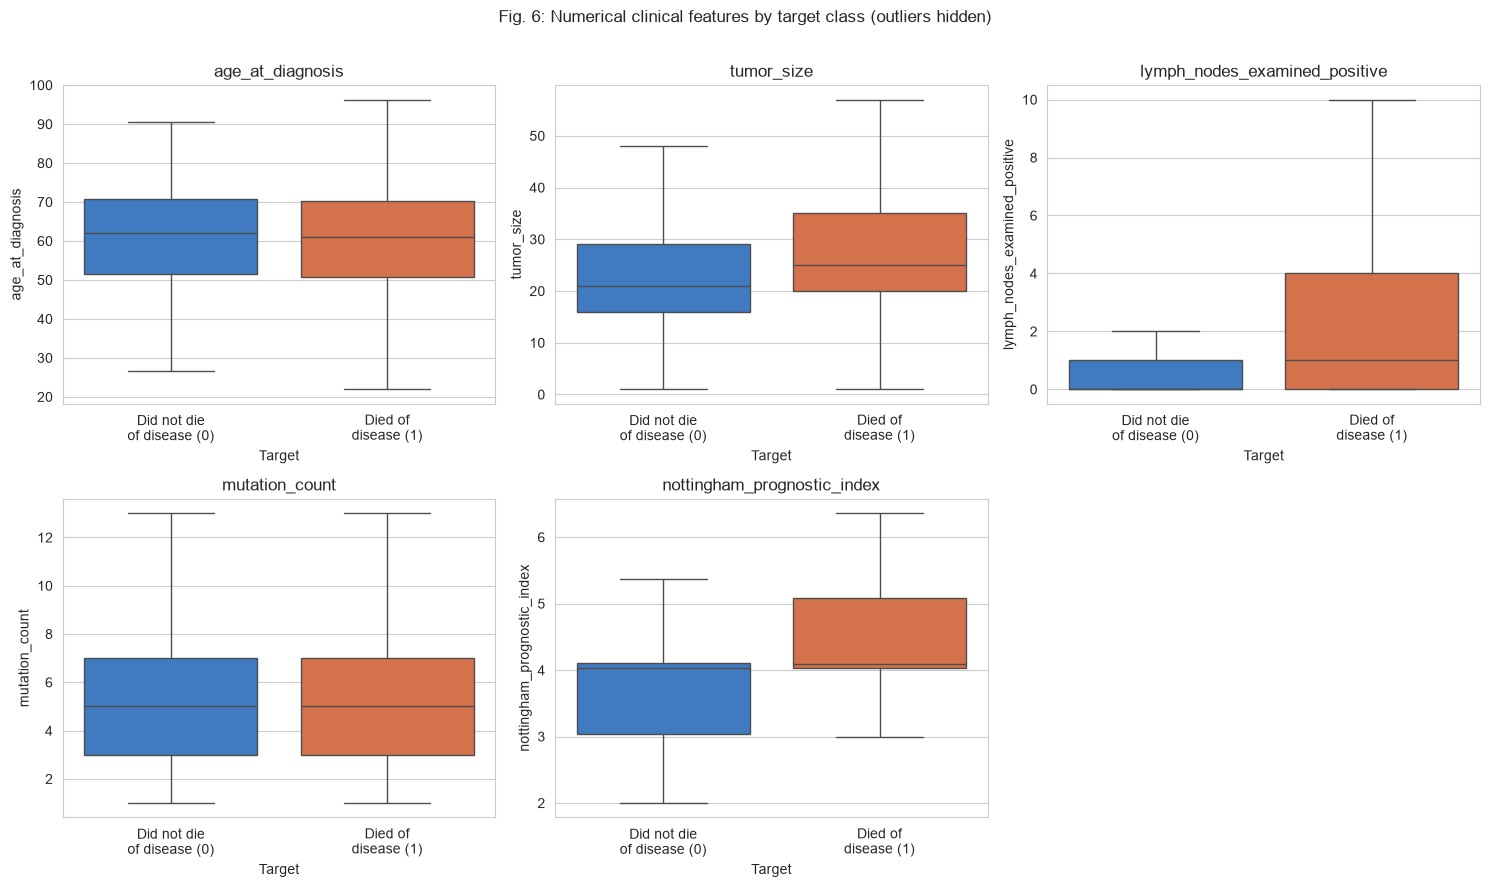

target,Did not die of disease (0),Died of disease (1)
age_at_diagnosis,61.99,61.14
tumor_size,21.00,25.00
lymph_nodes_examined_positive,0.00,1.00
mutation_count,5.00,5.00
nottingham_prognostic_index,4.04,4.10


In [35]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()
for ax, col in zip(axes, num_feats):
    sns.boxplot(data=eda, x='target', y=col, hue='target', palette={0: C0, 1: C1},
                showfliers=False, legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Did not die\nof disease (0)', 'Died of\ndisease (1)'])
    ax.set_title(col)
    ax.set_xlabel('Target')
    ax.set_ylabel(col)
axes[-1].axis('off')
fig.suptitle('Fig. 6: Numerical clinical features by target class (outliers hidden)')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

eda.groupby('target')[num_feats].median().T.rename(columns=TARGET_LABELS).round(2)

**Interpretation.** Patients who died of the disease had larger tumors (median 25 mm against 21 mm), more positive lymph nodes (median 1 against 0) and a higher NPI (the middle half of the group lies clearly higher, although the medians are close: 4.10 against 4.04). Age (61.1 against 62.0 years) and `mutation_count` (5 against 5) do not differ between the two classes.

## 3.8 Bivariate analysis: categorical features vs target

**What the next cell does:** for nine categorical features, computes the death-from-disease rate inside each category (the mean of the target) and draws it as a bar.
- The dashed line is the overall rate in the dataset. A bar above the line is a higher-risk group, a bar below it is a lower-risk group.
- Each label shows the number of patients `n` in the category, because a rate computed on a very small group is not reliable.

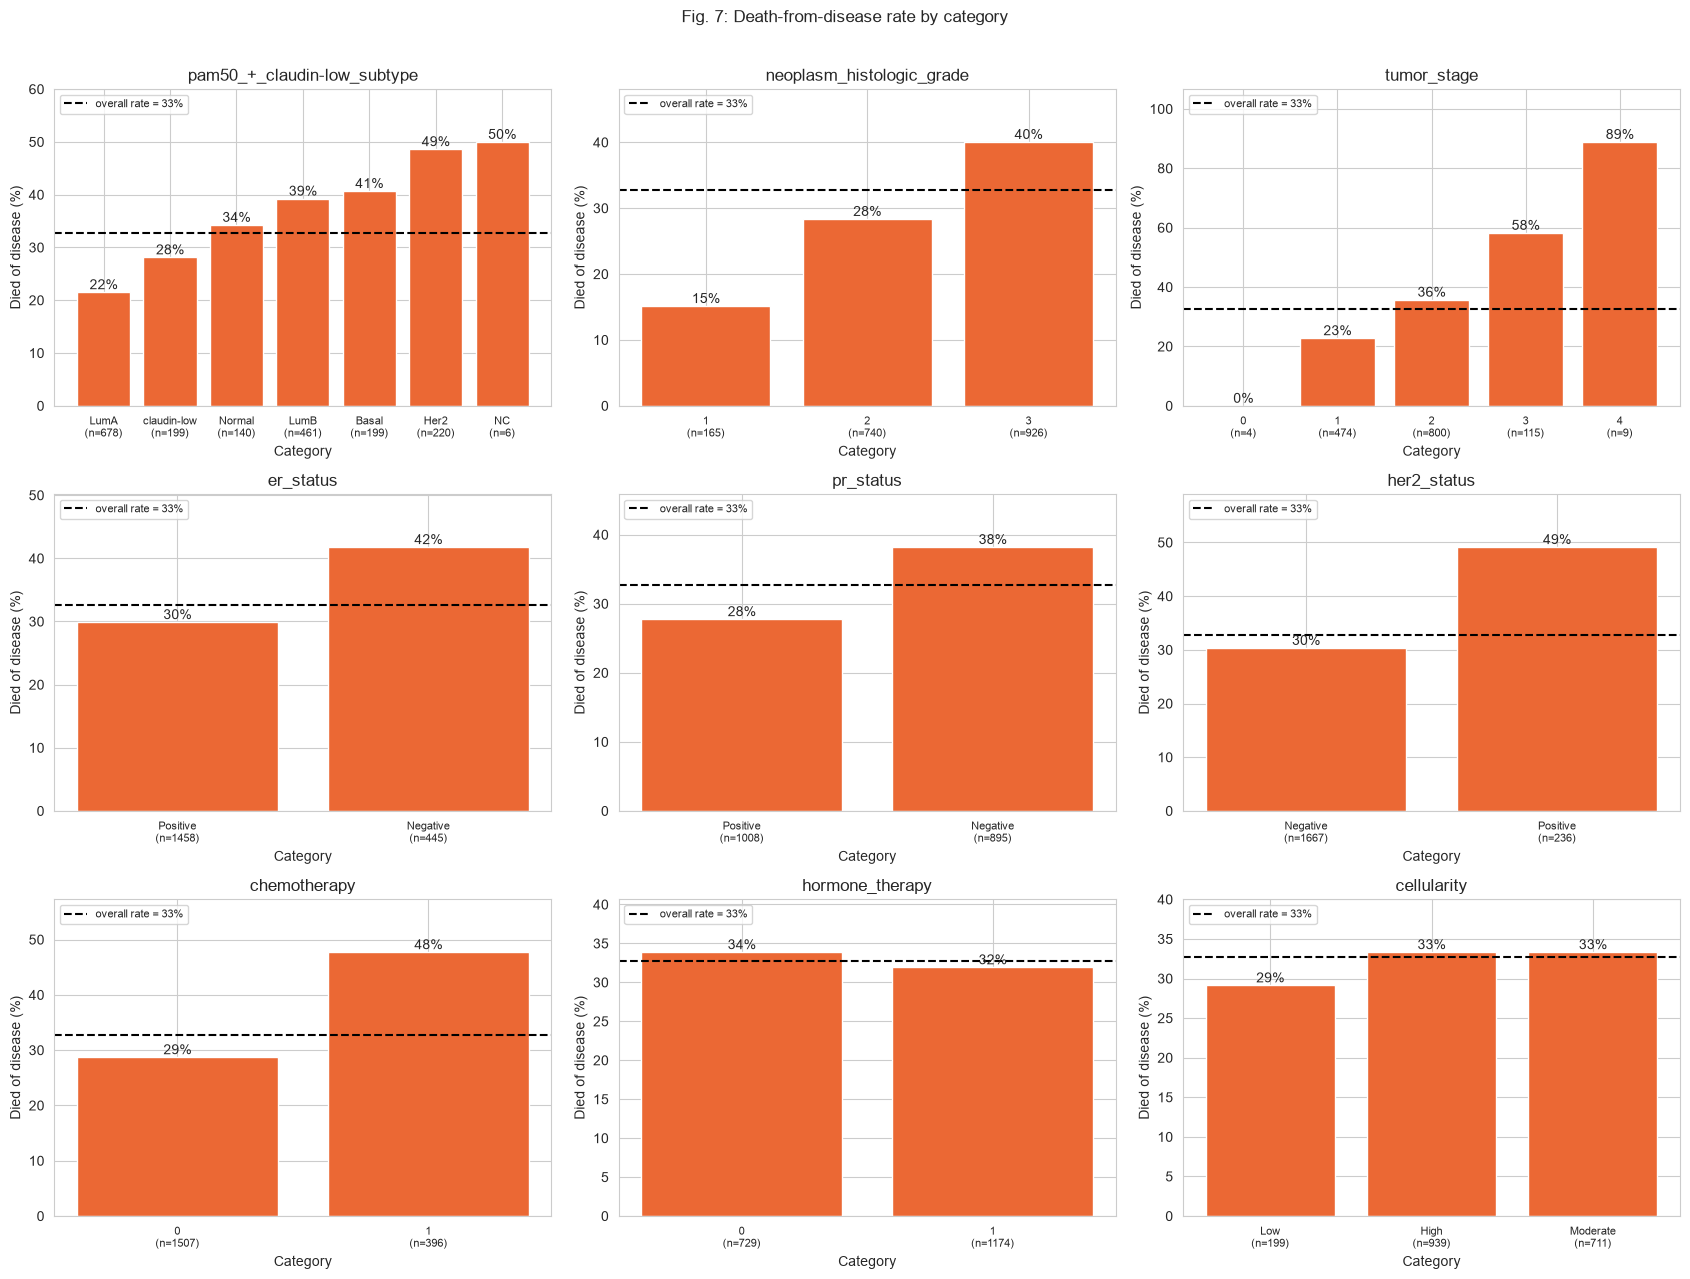

In [36]:
cat_vs_target = ['pam50_+_claudin-low_subtype', 'neoplasm_histologic_grade', 'tumor_stage',
                 'er_status', 'pr_status', 'her2_status',
                 'chemotherapy', 'hormone_therapy', 'cellularity']
overall_rate = eda['target'].mean() * 100

fig, axes = plt.subplots(3, 3, figsize=(17, 13))
for ax, col in zip(axes.ravel(), cat_vs_target):
    grp = eda.groupby(col)['target'].agg(['mean', 'size'])
    if not pd.api.types.is_numeric_dtype(eda[col]):
        grp = grp.sort_values('mean')
    labels = [f"{flag(v)}\n(n={n})" for v, n in zip(grp.index, grp['size'])]
    bars = ax.bar(labels, grp['mean'] * 100, color=C1)
    ax.bar_label(bars, fmt='%.0f%%')
    ax.axhline(overall_rate, color='black', linestyle='--', label=f"overall rate = {overall_rate:.0f}%")
    ax.set_title(col)
    ax.set_xlabel('Category')
    ax.set_ylabel('Died of disease (%)')
    ax.set_ylim(0, max(grp['mean'].max() * 100, overall_rate) * 1.2)
    ax.tick_params(axis='x', labelsize=8)
    ax.legend(loc='upper left', fontsize=8)
fig.suptitle('Fig. 7: Death-from-disease rate by category')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Interpretation.** The death rate rises steadily with tumor stage (23%, 36%, 58%, then 89% for the 9 stage-4 patients) and with grade (15%, 28%, 40%). It also differs by molecular profile: 49% for the Her2 subtype and 41% for Basal against 22% for Luminal A, 42% for ER-negative against 30% for ER-positive, and 49% for HER2-positive against 30% for HER2-negative. Patients who received chemotherapy died more often (48% against 29%), which reflects that chemotherapy is given to the most severe cases, not that it causes death. Hormone therapy and cellularity show almost no difference, and the 50% rate of the "NC" subtype rests on only 6 patients.

## 3.9 Correlation matrix (clinical features)

**What the next cell does:** computes the Spearman correlation between the numerical and ordinal clinical features and the target, and shows it as a heatmap.
- **Why Spearman and not Pearson:** Spearman works on ranks, so it is not distorted by the skewed features and outliers seen above, and it is suited to ordinal features such as grade and stage.
- Orange = positive correlation, blue = negative, light grey = no correlation.

Below the plot it prints the features ranked by correlation with the target, and the pairs of features that are strongly correlated with each other (|rho| ≥ 0.6), which is the sign of multicollinearity.

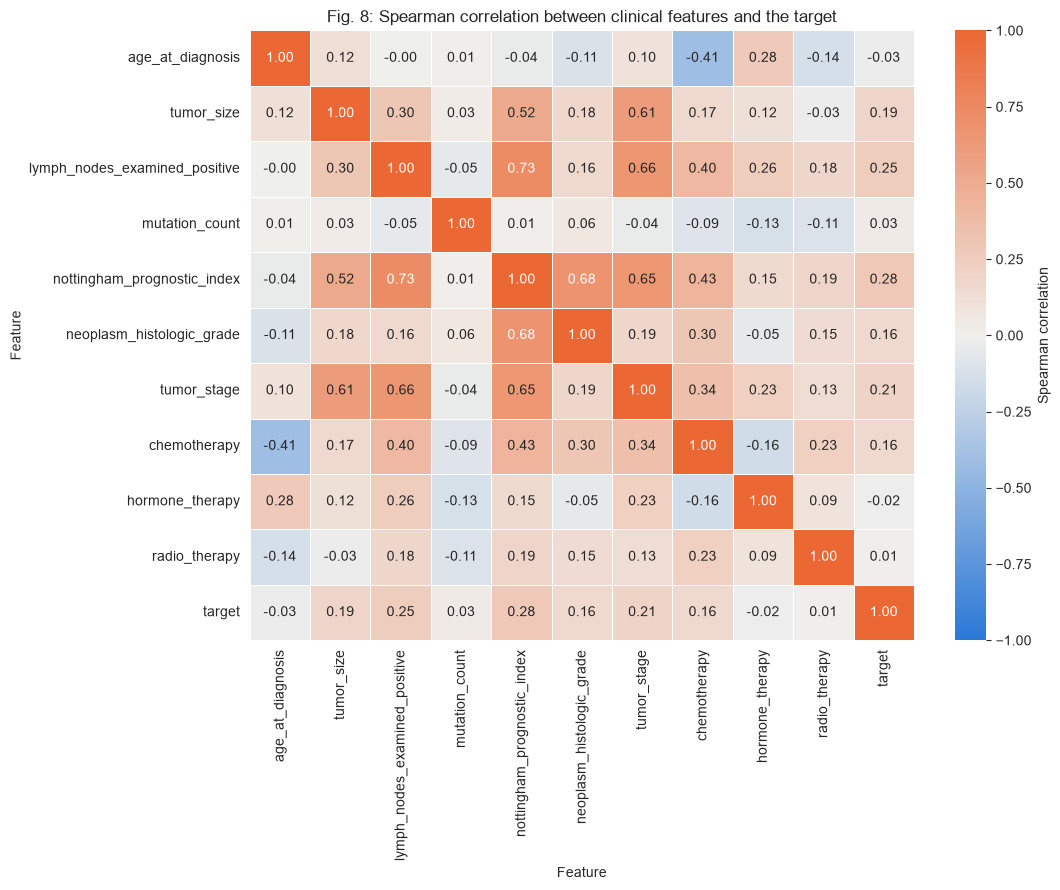

Correlation with the target:
nottingham_prognostic_index      0.281
lymph_nodes_examined_positive    0.255
tumor_stage                      0.208
tumor_size                       0.189
neoplasm_histologic_grade        0.164
chemotherapy                     0.164
mutation_count                   0.032
age_at_diagnosis                -0.028
hormone_therapy                 -0.020
radio_therapy                    0.011

Feature pairs with |rho| >= 0.6:
lymph_nodes_examined_positive  nottingham_prognostic_index    0.734
nottingham_prognostic_index    neoplasm_histologic_grade      0.675
lymph_nodes_examined_positive  tumor_stage                    0.659
nottingham_prognostic_index    tumor_stage                    0.652
tumor_size                     tumor_stage                    0.611


In [37]:
corr_feats = num_feats + ['neoplasm_histologic_grade', 'tumor_stage',
                          'chemotherapy', 'hormone_therapy', 'radio_therapy', 'target']
corr = eda[corr_feats].corr(method='spearman')

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap=CMAP_DIV, vmin=-1, vmax=1, center=0,
            linewidths=0.5, cbar_kws={'label': 'Spearman correlation'}, ax=ax)
ax.set_title('Fig. 8: Spearman correlation between clinical features and the target')
ax.set_xlabel('Feature')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()

print("Correlation with the target:")
print(corr['target'].drop('target').sort_values(key=abs, ascending=False).round(3).to_string())

pairs = corr.drop(index='target', columns='target').where(
    np.triu(np.ones((len(corr) - 1, len(corr) - 1), dtype=bool), k=1)).stack().dropna()
print("\nFeature pairs with |rho| >= 0.6:")
print(pairs[pairs.abs() >= 0.6].sort_values(key=abs, ascending=False).round(3).to_string())

**Interpretation.** The NPI is the clinical feature most correlated with the target (ρ = 0.28), followed by positive lymph nodes (0.26), tumor stage (0.21), tumor size (0.19), grade (0.16) and chemotherapy (0.16); age, mutation count, hormone therapy and radiotherapy are close to 0. No single feature is strongly predictive. There is clear multicollinearity: the NPI is correlated with the features it is computed from (lymph nodes 0.73, grade 0.68) and with stage (0.65), and stage is correlated with lymph nodes (0.66) and tumor size (0.61). This makes the coefficients of a linear model harder to interpret, which is one reason to use regularisation, while tree-based models are not affected.

## 3.10 Gene expression vs target

**What the next cell does:** measures how each of the 489 genes is linked to the target.
- It computes the Pearson correlation between each gene's expression and the binary target, then plots the 15 genes with the strongest correlation. An orange bar means the gene is more expressed in patients who died of the disease; a blue bar means it is less expressed.
- It then looks at correlations between genes: how many pairs of genes are strongly correlated with each other (|r| ≥ 0.8), which tells us whether the gene block is redundant.

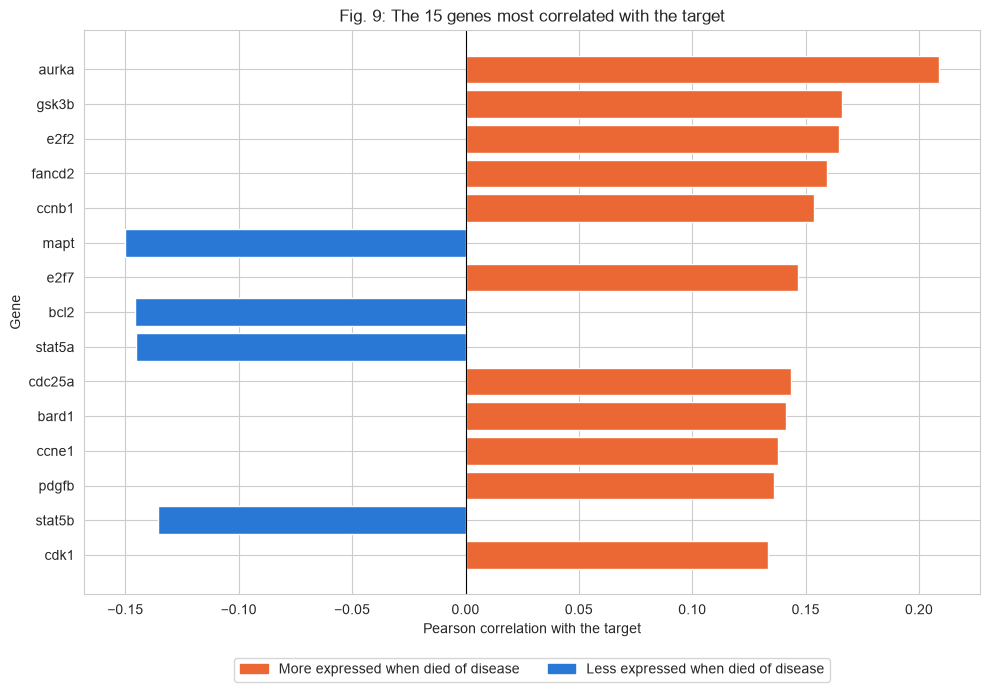

Strongest gene correlation with the target: 0.209 (aurka)
Genes with |r| >= 0.10: 41 of 489
Genes with |r| >= 0.15: 6 of 489

Gene pairs with |r| >= 0.8: 3 of 119316
Gene pairs with |r| >= 0.6: 96
Most correlated gene pairs:
akr1c2  akr1c4      0.875
akr1c3  akr1c4      0.833
pdgfrb  col6a3      0.824
tgfbr2  hsd17b11    0.781
mmp2    col6a3      0.744


In [38]:
gene_corr = eda[expr_cols].corrwith(eda['target'])
top_genes = gene_corr.reindex(gene_corr.abs().sort_values(ascending=False).index).head(15)[::-1]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_genes.index, top_genes.values, color=[C1 if v > 0 else C0 for v in top_genes.values])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Fig. 9: The 15 genes most correlated with the target')
ax.set_xlabel('Pearson correlation with the target')
ax.set_ylabel('Gene')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C1), plt.Rectangle((0, 0), 1, 1, color=C0)],
          labels=['More expressed when died of disease', 'Less expressed when died of disease'],
          loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()
plt.show()

print(f"Strongest gene correlation with the target: {gene_corr.abs().max():.3f} ({gene_corr.abs().idxmax()})")
print(f"Genes with |r| >= 0.10: {(gene_corr.abs() >= 0.10).sum()} of {len(expr_cols)}")
print(f"Genes with |r| >= 0.15: {(gene_corr.abs() >= 0.15).sum()} of {len(expr_cols)}")

gene_gene = eda[expr_cols].corr().where(np.triu(np.ones((len(expr_cols), len(expr_cols)), dtype=bool), k=1)).stack().dropna()
print(f"\nGene pairs with |r| >= 0.8: {(gene_gene.abs() >= 0.8).sum()} of {len(gene_gene)}")
print(f"Gene pairs with |r| >= 0.6: {(gene_gene.abs() >= 0.6).sum()}")
print("Most correlated gene pairs:")
print(gene_gene.sort_values(key=abs, ascending=False).head(5).round(3).to_string())

**Interpretation.** `aurka` is the gene most correlated with the target (r = 0.21), followed by `gsk3b`, `e2f2`, `fancd2` and `ccnb1` (0.15 to 0.17). Most of the genes that are more expressed in patients who died (`aurka`, `ccnb1`, `cdk1`, `e2f2`, `ccne1`, `cdc25a`) drive cell division, which fits fast-growing tumors, while `bcl2`, `mapt`, `stat5a` and `stat5b` are less expressed in these patients. Each gene is a weak predictor on its own: only 41 of 489 genes reach |r| ≥ 0.10 and 6 reach 0.15, so any gain from genomic data must come from combining many genes. Redundancy between genes is limited: 3 pairs out of 119,316 have |r| ≥ 0.8 and 96 have |r| ≥ 0.6.

## 3.11 Mutations

**What the next cell does:** turns each mutation column into a yes/no flag (`True` if the value is not `"0"`), then studies the genes mutated in at least 5% of patients.
- Left panel: the percentage of patients in which each gene is mutated.
- Right panel: the difference in death-from-disease rate between patients with and without the mutation, in percentage points. Orange = more deaths when the gene is mutated, blue = fewer.

It also prints how many genes pass the 5% threshold and the distribution of the number of mutated genes per patient.

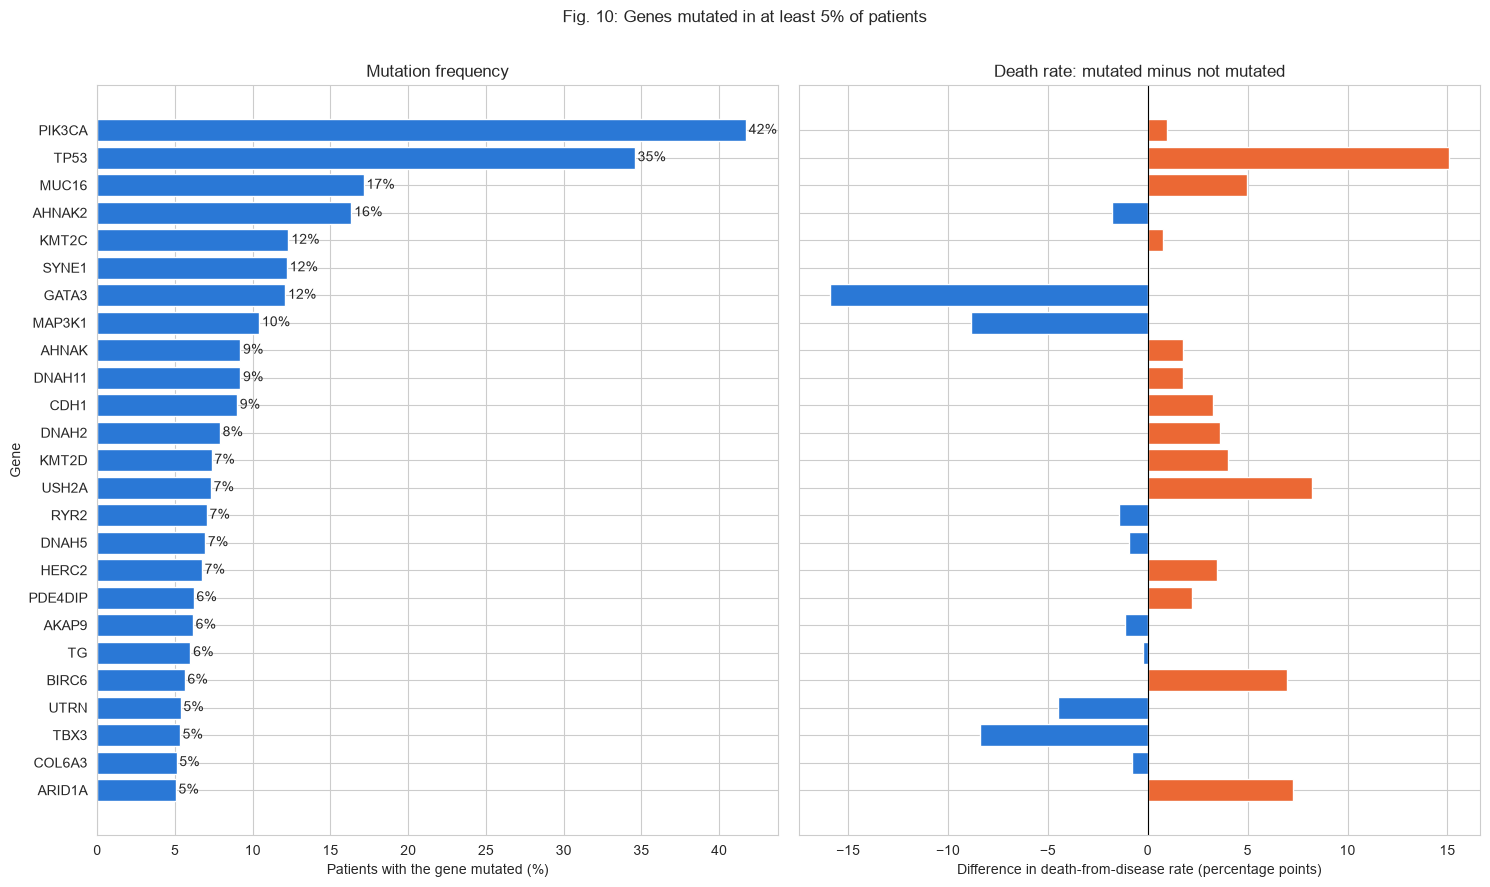

Share of mutated cells: 3.0%
Genes mutated in >= 5% of patients: 25 of 173
Genes never mutated: 0
Top 5 genes: PIK3CA 42%, TP53 35%, MUC16 17%, AHNAK2 16%, KMT2C 12%

Number of mutated genes per patient:
count    1903.00
mean        5.11
std         3.35
min         0.00
25%         3.00
50%         5.00
75%         6.50
max        48.00
Correlation of this number with the target (Spearman): 0.053


In [39]:
mut_flags = eda[mut_cols].astype(str) != '0'
mut_freq = mut_flags.mean() * 100
frequent = mut_freq[mut_freq >= 5].sort_values()

rate_diff = pd.Series({g: (eda.loc[mut_flags[g], 'target'].mean() - eda.loc[~mut_flags[g], 'target'].mean()) * 100
                       for g in frequent.index})
gene_names = [g.replace('_mut', '').upper() for g in frequent.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 9), sharey=True)
bars = axes[0].barh(gene_names, frequent.values, color=C0)
axes[0].bar_label(bars, fmt='%.0f%%', padding=2)
axes[0].set_title('Mutation frequency')
axes[0].set_xlabel('Patients with the gene mutated (%)')
axes[0].set_ylabel('Gene')

axes[1].barh(gene_names, rate_diff.values, color=[C1 if v > 0 else C0 for v in rate_diff.values])
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Death rate: mutated minus not mutated')
axes[1].set_xlabel('Difference in death-from-disease rate (percentage points)')

fig.suptitle('Fig. 10: Genes mutated in at least 5% of patients')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

n_mutated_genes = mut_flags.sum(axis=1)
print(f"Share of mutated cells: {mut_flags.mean().mean():.1%}")
print(f"Genes mutated in >= 5% of patients: {len(frequent)} of {len(mut_cols)}")
print(f"Genes never mutated: {(mut_freq == 0).sum()}")
print("Top 5 genes:", ', '.join(f"{g.replace('_mut', '').upper()} {v:.0f}%" for g, v in frequent[::-1].head(5).items()))
print("\nNumber of mutated genes per patient:")
print(n_mutated_genes.describe().round(2).to_string())
print(f"Correlation of this number with the target (Spearman): {n_mutated_genes.corr(eda['target'], method='spearman'):.3f}")

**Interpretation.** Mutations are sparse: only 3.0% of the cells are non-zero and 25 of the 173 genes are mutated in at least 5% of patients, led by PIK3CA (42%), TP53 (35%), MUC16 (17%) and AHNAK2 (16%). Frequency and prognostic value are different things: the death rate is about 15 points higher when TP53 is mutated and about 16 points lower when GATA3 is mutated, while PIK3CA, the most frequent mutation, changes it by about 1 point. A patient has a median of 5 mutated genes (maximum 48), and this number is almost unrelated to the target (ρ = 0.05).

## 3.12 Do the classes separate?

**What the next cell does:** draws a scatter plot of two clinical features, age at diagnosis and the NPI, with one point per patient coloured by class. If the two colours formed separate groups, a simple rule on these two features would be enough to classify patients. Overlapping colours mean the problem needs more features and a real model.

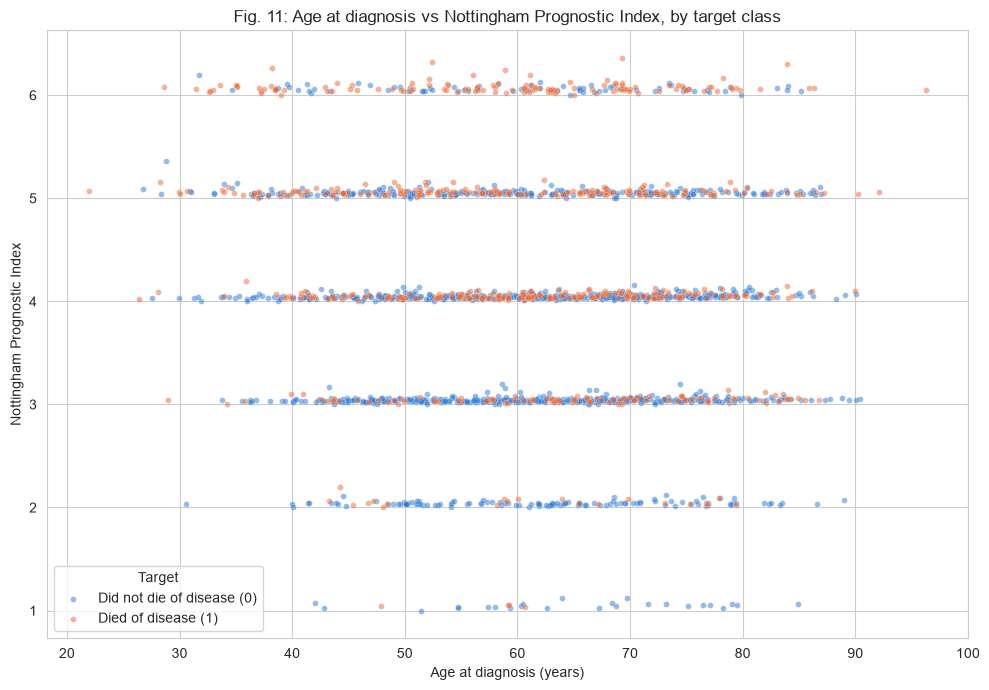

In [40]:
fig, ax = plt.subplots(figsize=(10, 7))
for cls, colour in [(0, C0), (1, C1)]:
    part = eda[eda['target'] == cls]
    ax.scatter(part['age_at_diagnosis'], part['nottingham_prognostic_index'],
               s=18, alpha=0.5, color=colour, edgecolor='white', linewidth=0.3, label=TARGET_LABELS[cls])
ax.set_title('Fig. 11: Age at diagnosis vs Nottingham Prognostic Index, by target class')
ax.set_xlabel('Age at diagnosis (years)')
ax.set_ylabel('Nottingham Prognostic Index')
ax.legend(title='Target')
plt.tight_layout()
plt.show()

**Interpretation.** The two classes overlap in every NPI band and at every age: there is no boundary that separates them. The share of orange points grows in the upper bands (NPI around 5 and 6), which confirms that the NPI carries signal but cannot classify patients on its own.

## 3.13 Summary of key findings

**1. Which features are most correlated with the target?**
Among clinical features, the NPI (ρ = 0.28), the number of positive lymph nodes (0.26), tumor stage (0.21), tumor size (0.19) and grade (0.16). Among categories, the Her2 and Basal subtypes, ER-negative and HER2-positive status are associated with more deaths. Among genes, `aurka` is the strongest (r = 0.21) and cell-division genes dominate the top 15. Among mutations, TP53 (more deaths) and GATA3 (fewer deaths) stand out. All these links are weak to moderate: no single feature predicts the outcome.

**2. Are there multicollinear features?**
Yes, in the clinical block: the NPI is built from tumor size, lymph nodes and grade (ρ up to 0.73), and tumor stage overlaps with lymph nodes and size. Several columns are redundant by construction (`er_status_measured_by_ihc` with `er_status`, and the three histology columns). The gene block has little redundancy (3 pairs with |r| ≥ 0.8).

**3. Are there obvious clusters or separations?**
No. The classes overlap on every pair of clinical features we examined. Risk increases gradually with stage, grade and NPI, without a clean boundary.

**4. How severe is the class imbalance?**
Moderate: 33% positive against 67% negative, a ratio of 2.06 to 1.

**Consequences for preprocessing (Phase 4)**

| Finding | Decision |
|---|---|
| 812 rows (42.6%) have a missing value | Impute inside the pipeline; do not drop rows |
| `tumor_stage` is missing for 26.3% of patients | Median imputation plus a missing-value indicator |
| Skewed features with medically plausible extremes | Keep the outliers; impute with the median |
| One "Breast Sarcoma" patient, one patient without target | Drop these two rows |
| `overall_survival`, `overall_survival_months`, `death_from_cancer`, `patient_id` | Remove from the features (leakage or identifier) |
| Redundant columns (`er_status_measured_by_ihc`, `cancer_type_detailed`, `oncotree_code`, `cancer_type`) | Drop |
| `cohort` is a group identifier | Treat as nominal, one-hot encode |
| Mutation columns are sparse text | Convert to 0/1 flags; keep the 25 genes mutated in at least 5% of patients; add the number of mutated genes |
| 299 triple-negative patients | Create the feature `triple_negative` |
| Imbalance of 2.06 to 1 | Stratified split and class weights |
| Features on very different scales | Standardise numerical features |